# Exploratory Data Analysis of Solar PV Production

## 1. Introduction

Solar photovoltaic (PV) systems convert solar energy into electricity. Understanding their electricity production patterns is important for renewable energy planning, system performance assessment, and energy forecasting.

This project investigates historical solar electricity production data from photovoltaic installations operated by the City of Calgary, Canada.

The analysis will use Python to inspect, clean, preprocess, and visualize the dataset. Particular attention will be given to temporal production patterns, differences between installations, data quality, and the potential use of historical production data for energy forecasting.

### Project objectives

- Understand the structure and characteristics of the dataset.
- Identify and address data quality issues.
- Analyze temporal patterns in solar electricity production.
- Compare production across photovoltaic installations where appropriate.
- Identify insights relevant to renewable energy assessment and forecasting.

### Dataset

- **Dataset name:** Solar Production (Photovoltaic Output Data)
- **File:** Solar_Energy_Production.csv
- **Main variable of interest:** Energy production (kWh)

### Research question

How does photovoltaic electricity production vary over time and across installations, and what can historical production data reveal about generation patterns and forecasting potential?

In [1]:
# Import the libraries required for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure the default visualization style
sns.set_theme(style="whitegrid")

# Display plots directly inside the notebook
%matplotlib inline

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading and Inspection

The dataset is stored in CSV format. The pandas library will be used to import the file into a DataFrame, which allows the data to be examined and processed.

The initial inspection will verify that the file has been loaded correctly before assessing its structure, variable types, and statistical characteristics.

In [2]:
# Load the solar production dataset

from pathlib import Path

file_path = Path("../data/Solar_Energy_Production.csv")

df = pd.read_csv(file_path)

# Confirm that the dataset was loaded
print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display the first five records
display(df.head())

Dataset loaded successfully.
Number of rows: 258,423
Number of columns: 8


,name,id,address,date,kWh,public_url,installationDate,uid
0,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 08:00:00 AM,1.130,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 08:00:00
1,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 09:00:00 AM,2.340,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 09:00:00
2,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 10:00:00 AM,3.656,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 10:00:00
3,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 11:00:00 AM,4.577,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 11:00:00
4,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 12:00:00 PM,6.506,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 12:00:00


### 2.1 Initial Dataset Inspection

The dataset will be examined using its dimensions, column names, data types, and descriptive statistics. This step helps identify the variables available for analysis and highlights potential issues that may require preprocessing.

In [3]:
# Inspect column names, data types, and non-null counts
df.info()

# Generate descriptive statistics
display(df.describe(include="all"))

# Check for missing values in each column
display(df.isnull().sum())

# Check for exact duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258423 entries, 0 to 258422
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   name              258423 non-null  object 
 1   id                258423 non-null  int64  
 2   address           258423 non-null  object 
 3   date              258423 non-null  object 
 4   kWh               258423 non-null  float64
 5   public_url        258423 non-null  object 
 6   installationDate  258423 non-null  object 
 7   uid               258423 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 15.8+ MB


,name,id,address,date,kWh,public_url,installationDate,uid
count,258423,258423.000000,258423,258423,258423.000000,258423,258423,258423
unique,11,NaN,11,36192,NaN,22,11,258423
top,Southland Leisure Centre,NaN,2000 SOUTHLAND DR SW,2017/12/05 04:00:00 PM,NaN,https://monitoringpublic.solaredge.com/solared...,2015/09/01,3141062017-09-11 08:00:00
freq,31590,NaN,31590,11,NaN,24533,31590,1
mean,NaN,372581.033132,NaN,NaN,38.059762,NaN,NaN,NaN
std,NaN,130344.544572,NaN,NaN,71.598031,NaN,NaN,NaN
min,NaN,164440.000000,NaN,NaN,0.000000,NaN,NaN,NaN
25%,NaN,314106.000000,NaN,NaN,1.370000,NaN,NaN,NaN
50%,NaN,331901.000000,NaN,NaN,8.034000,NaN,NaN,NaN
75%,NaN,551172.000000,NaN,NaN,35.876000,NaN,NaN,NaN


name                0
id                  0
address             0
date                0
kWh                 0
public_url          0
installationDate    0
uid                 0
dtype: int64

Number of duplicate rows: 0


### 2.2 Data Quality Assessment

The initial inspection indicates that the dataset contains no
missing values in the displayed columns and no exact duplicate
rows. However, further checks are required to assess timestamp
validity, chronological consistency, and gaps in the recorded
production data.

The next step is to convert the date columns to appropriate
datetime formats and examine the range and distribution of
the recorded energy production values.

In [4]:

# Inspect the date columns and energy production values

print("Column names:")
print(df.columns.tolist())

# Convert date columns to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["installationDate"] = pd.to_datetime(
    df["installationDate"], errors="coerce"
)

# Check whether any dates failed to parse
print("\nInvalid or missing production dates:", df["date"].isna().sum())
print("Invalid or missing installation dates:",
      df["installationDate"].isna().sum())

# Examine the date range
print("\nProduction date range:")
print("Earliest:", df["date"].min())
print("Latest:", df["date"].max())

# Examine the energy production variable
print("\nEnergy production summary:")
display(df["kWh"].describe())

print("\nNegative energy readings:", (df["kWh"] < 0).sum())
print("Zero energy readings:", (df["kWh"] == 0).sum())


Column names:
['name', 'id', 'address', 'date', 'kWh', 'public_url', 'installationDate', 'uid']

Invalid or missing production dates: 0
Invalid or missing installation dates: 0

Production date range:
Earliest: 2015-09-01 14:30:00
Latest: 2023-03-16 19:00:00

Energy production summary:


count    258423.000000
mean         38.059762
std          71.598031
min           0.000000
25%           1.370000
50%           8.034000
75%          35.876000
max         514.462000
Name: kWh, dtype: float64


Negative energy readings: 0
Zero energy readings: 1176


### 2.3 Interpretation of Initial Data Quality Results

The dataset contains 258,423 observations, with production
timestamps ranging from September 1, 2015, to March 16, 2023.

The datetime conversion was successful, with no invalid or
missing values detected in the production and installation
date columns.

The energy production variable has a mean of approximately
38.06 kWh and a median of 8.034 kWh. The substantial
difference between these values suggests a positively
skewed distribution.

The minimum recorded production is 0 kWh, while the maximum
is approximately 514.46 kWh. No negative production values
were identified.

A total of 1,176 zero-production observations were detected.
These values will be retained during the initial analysis,
as they may represent legitimate operating conditions.

Further investigation is required to identify potential
temporal gaps, inconsistent records, and production outliers.

## 3. Data Cleaning and Preprocessing

### 3.1 Installation-Level Data Assessment

The dataset contains electricity production measurements
from multiple photovoltaic installations.

Before performing temporal resampling and outlier detection,
the number of observations, recording periods, and production
characteristics of each installation will be examined.

This assessment will help identify differences in data
coverage and system behavior.

In [5]:

# Examine the number of PV installations
print("Number of unique installations:", df["id"].nunique())

# Summarize observations and energy production by installation
installation_summary = (
    df.groupby(["id", "name"])
    .agg(
        observations=("kWh", "size"),
        first_record=("date", "min"),
        last_record=("date", "max"),
        mean_energy_kWh=("kWh", "mean"),
        max_energy_kWh=("kWh", "max"),
        total_energy_kWh=("kWh", "sum")
    )
    .reset_index()
)

# Display the installation-level summary
display(installation_summary.round(2))

# Check repeated timestamps within the same installation
duplicate_timestamps = df.duplicated(
    subset=["id", "date"]
).sum()

print("Duplicate installation-timestamp records:",
      duplicate_timestamps)


Number of unique installations: 11


,id,name,observations,first_record,last_record,mean_energy_kWh,max_energy_kWh,total_energy_kWh
0,164440,Southland Leisure Centre,31590,2015-09-01 14:30:00,2023-03-16 18:00:00,36.32,123.62,1147493.63
1,308057,Hillhurst Sunnyside Community Association,23467,2016-10-03 13:00:00,2023-03-15 19:00:00,7.94,29.00,186441.26
2,314106,Calgary Fire Hall Headquarters,25637,2016-11-24 14:00:00,2023-03-16 19:00:00,4.30,16.60,110211.61
3,319086,Whitehorn Multi-Service Centre,27716,2017-02-13 09:45:00,2023-03-16 19:00:00,92.32,369.06,2558802.50
4,331901,City of Calgary North Corporate Warehouse,27092,2016-12-23 09:30:00,2023-03-16 19:00:00,28.38,102.86,768964.64
5,332785,Richmond - Knob Hill Community Hall,26623,2016-12-09 11:00:00,2023-03-16 19:00:00,2.82,9.28,75130.28
6,355827,Glenmore Water Treatment Plant,25920,2017-03-08 10:00:00,2023-03-12 17:00:00,59.84,239.97,1551177.72
7,551172,CFD Firehall #7,22659,2017-09-21 07:00:00,2023-03-16 19:00:00,7.51,29.21,170080.89
8,570079,Manchester Building M,22533,2017-10-05 13:15:00,2023-03-16 19:00:00,8.13,34.12,183243.24
9,577650,Bearspaw Water Treatment Plant,24869,2017-11-21 10:45:00,2023-03-16 19:00:00,123.96,514.46,3082637.60


Duplicate installation-timestamp records: 0


### 3.2 Interpretation of Installation-Level Assessment

The dataset contains 11 photovoltaic installations with
different observation counts, recording periods, and
electricity production characteristics.

Bearspaw Water Treatment Plant recorded the highest
average electricity production among the installations,
at approximately 123.96 kWh per observation, with a
maximum recorded value of 514.46 kWh.

Whitehorn Multi-Service Centre also exhibited relatively
high production, with an average of approximately
92.32 kWh per observation.

In contrast, Richmond–Knob Hill Community Hall recorded
a much lower average production of approximately
2.82 kWh per observation.

The Telus Spark installation contains only 317
observations, indicating substantially shorter data
coverage than most other installations.

No duplicate installation-timestamp combinations
were detected.

These findings demonstrate that production
characteristics and recording coverage vary
considerably across installations.

Consequently, installation-level differences should
be considered during preprocessing, outlier detection,
and comparative analysis.

### 3.3 Temporal Consistency and Missing Interval Assessment

Although the dataset contains no missing datetime values,
some expected recording intervals may be absent.

This section examines the time differences between
consecutive observations for each PV installation.

The objective is to identify recording frequencies,
potential temporal gaps, and inconsistencies that may
affect time-series analysis and forecasting.

In [6]:

# Sort observations chronologically within each installation
df = df.sort_values(["id", "date"]).copy()

# Calculate time differences between consecutive observations
df["time_difference"] = (
    df.groupby("id")["date"].diff()
)

# Summarize the most common recording intervals
print("Most common recording intervals:")
display(df["time_difference"].value_counts().head(15))

# Count intervals longer than one hour
long_gaps = df["time_difference"] > pd.Timedelta(hours=1)

print("\nNumber of intervals longer than one hour:",
      long_gaps.sum())

# Summarize temporal gaps by installation
gap_summary = (
    df.assign(
        gap_over_1h=long_gaps,
        gap_over_24h=(
            df["time_difference"] > pd.Timedelta(hours=24)
        )
    )
    .groupby(["id", "name"])
    .agg(
        observations=("date", "size"),
        gaps_over_1h=("gap_over_1h", "sum"),
        gaps_over_24h=("gap_over_24h", "sum"),
        median_interval=("time_difference", "median")
    )
    .reset_index()
)

display(gap_summary)


Most common recording intervals:


time_difference
0 days 01:00:00    236611
0 days 08:00:00      2719
0 days 16:00:00      2698
0 days 10:00:00      2657
0 days 12:00:00      2202
0 days 09:00:00      1909
0 days 14:00:00      1714
0 days 15:00:00      1449
0 days 11:00:00      1325
0 days 13:00:00      1277
0 days 17:00:00      1027
0 days 18:00:00       646
0 days 00:15:00       349
0 days 00:45:00       337
0 days 19:00:00       303
Name: count, dtype: int64


Number of intervals longer than one hour: 21089


,id,name,observations,gaps_over_1h,gaps_over_24h,median_interval
0,164440,Southland Leisure Centre,31590,2586,43,0 days 01:00:00
1,308057,Hillhurst Sunnyside Community Association,23467,2016,87,0 days 01:00:00
2,314106,Calgary Fire Hall Headquarters,25637,2133,28,0 days 01:00:00
3,319086,Whitehorn Multi-Service Centre,27716,2201,8,0 days 01:00:00
4,331901,City of Calgary North Corporate Warehouse,27092,2211,16,0 days 01:00:00
5,332785,Richmond - Knob Hill Community Hall,26623,2205,36,0 days 01:00:00
6,355827,Glenmore Water Treatment Plant,25920,2067,36,0 days 01:00:00
7,551172,CFD Firehall #7,22659,1882,20,0 days 01:00:00
8,570079,Manchester Building M,22533,1877,21,0 days 01:00:00
9,577650,Bearspaw Water Treatment Plant,24869,1873,6,0 days 01:00:00


### 3.4 Interpretation of Temporal Consistency

The temporal consistency assessment indicates that
the dataset predominantly follows an hourly recording
frequency.

A total of 236,611 consecutive observations were
separated by exactly one hour, representing approximately
91.6% of the within-installation intervals.

However, 21,089 intervals exceeded one hour, indicating
discontinuities in the recorded time series.

Several common gaps ranged between 8 and 16 hours.
These intervals may correspond to overnight periods
when photovoltaic electricity generation is limited
or absent.

All 11 installations exhibited a median recording
interval of one hour.

Hillhurst Sunnyside Community Association recorded
87 intervals exceeding 24 hours, the highest among
the installations examined.

These findings suggest that the dataset has a
predominantly hourly structure but is not a fully
continuous hourly time series.

Consequently, temporal resampling should be performed
carefully to avoid treating unrecorded observations
as confirmed zero electricity production.

### 3.5 Distribution of Recording Hours

This section examines the distribution of observations
across the 24 hours of the day.

The objective is to identify whether recorded production
measurements are concentrated during daylight hours
and to assess how the recording schedule may influence
the interpretation of temporal gaps.

,Number of observations
hour,
0,125
1,125
2,114
3,110
4,107
5,3007
6,7486
7,12199
8,17916


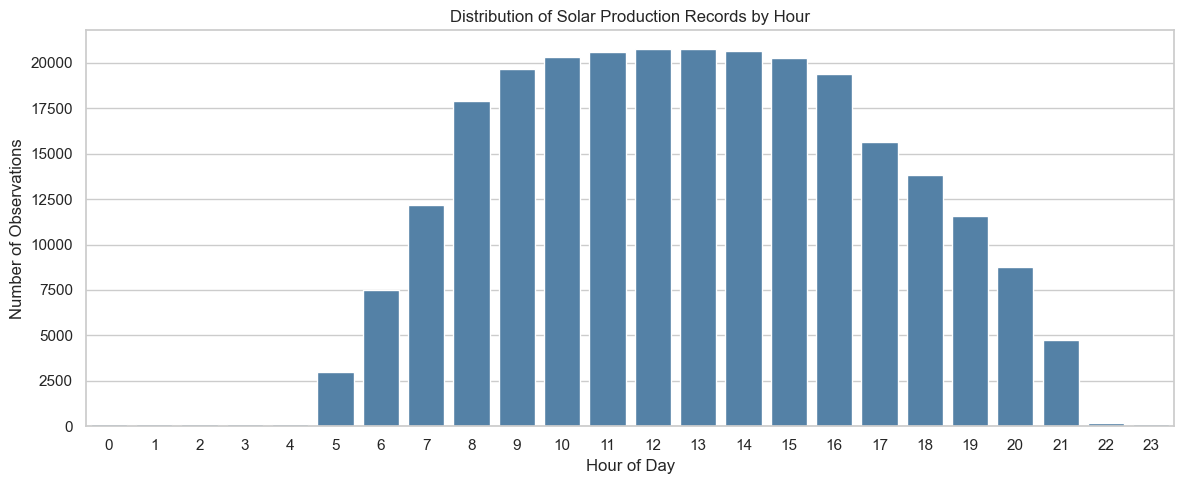

In [7]:

# Extract the hour from each production timestamp
df["hour"] = df["date"].dt.hour

# Count observations for each hour
hourly_counts = (
    df["hour"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

# Display the hourly observation counts
display(
    hourly_counts.rename("Number of observations").to_frame()
)

# Plot the distribution of observations by hour
plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_counts.index,
    y=hourly_counts.values,
    color="steelblue"
)

plt.title("Distribution of Solar Production Records by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Observations")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


### 3.6 Interpretation of Recording Hour Distribution

The distribution of recorded observations shows a
strong concentration during daylight hours.

Very few or no observations are available during
the early morning hours between midnight and 04:00.

The number of records increases from approximately
05:00 and reaches its highest concentration
between 10:00 and 15:00.

After approximately 16:00, the number of recorded
observations gradually decreases, with very few
records remaining after 21:00.

This pattern is consistent with the operating
characteristics of photovoltaic systems.

The results also provide a possible explanation
for the frequent overnight gaps identified during
the temporal consistency assessment.

However, this visualization represents observation
frequency rather than electricity generation.

Additional analysis of hourly energy production
is required to identify actual production peaks.

Unrecorded nighttime intervals will not
automatically be replaced with zero values.

### 3.7 Feature Engineering

Feature engineering involves creating new variables from
existing data to support analysis and visualization.

In this study, temporal features will be extracted from
the production timestamps, including the hour, day,
month, year, and season.

These features will help investigate daily and seasonal
variations in photovoltaic electricity generation.

In [8]:

# Create time-based features from production timestamps

df["hour"] = df["date"].dt.hour
df["day"] = df["date"].dt.day
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
df["day_of_week"] = df["date"].dt.dayofweek

# Assign meteorological seasons for Calgary
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["season"] = df["month"].apply(get_season)

# Inspect the newly created features
display(
    df[[
        "date", "hour", "day", "month",
        "year", "day_of_week", "season", "kWh"
    ]].head(10)
)

# Confirm the new DataFrame dimensions
print("Updated dataset shape:", df.shape)


,date,hour,day,month,year,day_of_week,season,kWh
23003,2015-09-01 14:30:00,14,1,9,2015,1,Autumn,27.805
23005,2015-09-01 15:30:00,15,1,9,2015,1,Autumn,30.559
23006,2015-09-01 16:30:00,16,1,9,2015,1,Autumn,23.613
23007,2015-09-01 17:30:00,17,1,9,2015,1,Autumn,15.257
23008,2015-09-01 18:30:00,18,1,9,2015,1,Autumn,7.896
23009,2015-09-01 19:30:00,19,1,9,2015,1,Autumn,1.885
23010,2015-09-01 20:30:00,20,1,9,2015,1,Autumn,41.066
23011,2015-09-01 21:30:00,21,1,9,2015,1,Autumn,57.844
23012,2015-09-01 22:30:00,22,1,9,2015,1,Autumn,48.606
23013,2015-09-01 23:30:00,23,1,9,2015,1,Autumn,31.482


Updated dataset shape: (258423, 15)
